# Fiber Intake Explorer — Reproducible CNF 2026 preparation and EDA

**Input:** official CNF 2026 relational CSV files; **output:** cleaned and recommendation-ready foods. One record corresponds to one CNF food code / preparation-specific food profile. Data preparation uses actual `Food_Code`, `Nutrient_Code`, and `CNF_Food_Group_Code` keys. Source: Health Canada (2026), *Canadian Nutrient File users’ guide* and *Database structure and file content description*.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_DIR / 'data'
sys.path.insert(0, str(PROJECT_DIR))
from food_features import add_food_features, classify_form
print('Project root:', PROJECT_DIR)

Project root: C:\Users\kuma0\Documents\CMSE830-Fall2026\Fiber-Intake-Explorer-Updated


## 1. Source and raw table inspection

**Source:** Health Canada, *Canadian Nutrient File (CNF)* (the user's locally downloaded `cnf_fcen_all-files-data_2026` release). Food metadata, nutrient amounts, nutrient dictionary, and CNF food groups are stored separately and are linked through food/nutrient identifiers.

The original CNF CSV files are **not included** in the portable project: place them in `data/cnf_fcen_all-files-data_2026/` to repeat raw-table checks. The later sections run using the supplied cleaned export even without original files.

In [2]:
RAW_DIR = DATA_DIR / "cnf_fcen_all-files-data_2026"
required = ["Food_Name.csv", "Nutrient_Amount.csv", "Nutrient_Name.csv", "CNF_Food_Group.csv"]
missing = [f for f in required if not (RAW_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing official CNF source files in {RAW_DIR}: {missing}")
raw_tables = {Path(f).stem: pd.read_csv(RAW_DIR / f) for f in required}
for name, frame in raw_tables.items():
    print(f"{name}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")
    display(frame.head(3))
food_names, nut_amounts, nut_names, food_groups = [raw_tables[x] for x in ['Food_Name','Nutrient_Amount','Nutrient_Name','CNF_Food_Group']]
assert food_names.Food_Code.is_unique
assert nut_names.Nutrient_Code.is_unique
assert food_groups.CNF_Food_Group_Code.is_unique
assert not nut_amounts.duplicated(['Food_Code','Nutrient_Code']).any()
print('Food name missing fields:')
display(food_names.isna().sum().sort_values(ascending=False).to_frame('missing'))

Food_Name: 5,993 rows × 12 columns


,Food_Code,Food_Description_EN,Food_Description_FR,Alternate_Description_EN,Alternate_Description_FR,Food_Source_Code,USDA_NDB_Code,CNF_Food_Group_Code,Comment_EN,Comment_FR,ScientificName,Food_Last_Updated_Date
0,2,Cheese souffle,Soufflé au fromage,NaN,NaN,20,NaN,22,NaN,NaN,NaN,2012-06-28
1,4,"Chop suey, with meat, canned","Chop suey, avec viande, conserve",NaN,chopsuey,20,NaN,22,NaN,NaN,NaN,2026-01-28
2,5,"Chinese dish, chow mein, chicken","Mets chinois, chow mein, poulet",NaN,NaN,0,36623.0,22,Rice not included in the analyses. May includ...,Riz non inclus dans l'analyse. Peut inclure: o...,NaN,2026-01-28


Nutrient_Amount: 565,409 rows × 7 columns


,Food_Code,Nutrient_Code,Nutrient_Amount,STD_Error,Observations,Nutrient_Source_Code,Nutrient_Last_Updated_Date
0,2,203,9.54415,0.0,0.0,51,2010-04-16
1,2,204,15.70470,0.0,0.0,51,2010-04-16
2,2,205,5.91100,0.0,0.0,51,2010-04-16


Nutrient_Name: 173 rows × 7 columns


,Nutrient_Code,Nutrient_Symbol,Nutrient_Unit,Nutrient_Name_EN,Nutrient_Name_FR,Tagname,Nutrient_Decimals
0,203,PROT,Gram,Protein,Protéines,PROCNT,2
1,204,FAT,Gram,Fat (total lipids),Lipides totaux,FAT,2
2,205,CARB,Gram,"Carbohydrate, total (by difference)",Glucides totaux (par différence),CHOCDF,2


CNF_Food_Group: 23 rows × 3 columns


,CNF_Food_Group_Code,CNF_Food_Group_Description_EN,CNF_Food_Group_Description_FR
0,1,Dairy and Egg Products,Produits laitiers et d'oeufs
1,2,Spices and Herbs,Épices et fines herbes
2,3,Babyfoods,Aliments pour bébés


Food name missing fields:


,missing
Comment_EN,5496
Comment_FR,5496
ScientificName,5087
Alternate_Description_EN,4609
Alternate_Description_FR,3734
USDA_NDB_Code,1195
Food_Code,0
Food_Description_EN,0
Food_Description_FR,0
Food_Source_Code,0


## 2. Data integration, missingness, and cleaning

Official CNF 2026: `Food_Name` is keyed by `Food_Code`; `Nutrient_Amount` contains one food–nutrient record, where `Nutrient_Code=291` denotes total dietary fibre (g/100 g) and `208` denotes energy (kcal/100 g). Food group codes 9, 11, and 16 identify fruits, vegetables and legumes. **Missing is unknown, not zero** (CNF Users’ Guide, p. 10); we therefore exclude profiles with unavailable fiber or energy from numeric recommendation calculations rather than imputing zero. Report losses explicitly. Retain recorded fiber = 0 in the cleaned dataset; the recommendation app may screen them out as non-contributing candidates.

In [3]:
# Inspect the two nutrient definitions and group labels, without hard-coding nutrient names.
display(nut_names[nut_names.Nutrient_Code.isin([291,208])][['Nutrient_Code','Nutrient_Name_EN','Nutrient_Unit']])
display(food_groups[food_groups.CNF_Food_Group_Code.isin([9,11,16])])
profile_nutrients = nut_amounts[nut_amounts.Nutrient_Code.isin([291,208])].copy()
pivoted = profile_nutrients.pivot(index='Food_Code',columns='Nutrient_Code',values='Nutrient_Amount').rename(columns={291:'fiber_per_100g',208:'calories_per_100g'}).reset_index()
joined = food_names.merge(food_groups,on='CNF_Food_Group_Code',how='left',validate='many_to_one').merge(pivoted,on='Food_Code',how='left',validate='one_to_one')
joined['category']=joined.CNF_Food_Group_Code.map({9:'Fruit',11:'Vegetable',16:'Legume'})
scoped = joined[joined.category.notna()].copy()
print('Within target 3 CNF categories, before dropping rows:', len(scoped))
print('Missing fiber:', scoped.fiber_per_100g.isna().sum())
print('Missing kcal:', scoped.calories_per_100g.isna().sum())
print('Missing both:', (scoped.fiber_per_100g.isna() & scoped.calories_per_100g.isna()).sum())
cleaned = scoped.dropna(subset=['fiber_per_100g','calories_per_100g']).copy()
negative = (cleaned[['fiber_per_100g','calories_per_100g']]<0).any(axis=1)
print('Invalid negative rows:',negative.sum())
cleaned = cleaned[~negative].copy()
print('Retained:', len(cleaned), 'zero-fiber entries:', (cleaned.fiber_per_100g==0).sum())
assert cleaned.Food_Code.is_unique
cleaned.to_csv(DATA_DIR/'fiber_data.csv',index=False)
display(cleaned[['Food_Code','Food_Description_EN','category','fiber_per_100g','calories_per_100g']].head())

,Nutrient_Code,Nutrient_Name_EN,Nutrient_Unit
4,208,Energy (kilocalories),kilocalorie
19,291,"Fibre, total dietary",Gram


,CNF_Food_Group_Code,CNF_Food_Group_Description_EN,CNF_Food_Group_Description_FR
8,9,Fruits and fruit juices,Fruits et jus de fruits
10,11,Vegetables and Vegetable Products,Légumes et produits végétaux
15,16,Legumes and Legume Products,Légumineuses et produits de légumineuses


Within target 3 CNF categories, before dropping rows: 1353
Missing fiber: 113
Missing kcal: 0
Missing both: 0
Invalid negative rows: 0
Retained: 1240 zero-fiber entries: 7


,Food_Code,Food_Description_EN,category,fiber_per_100g,calories_per_100g
810,1484,"Acerola (West Indian cherry), raw",Fruit,1.1,32.0
811,1485,"Acerola (West Indian cherry), juice, raw",Fruit,0.3,23.0
812,1486,"Apple, raw, without skin, sliced, cooked, micr...",Fruit,2.8,56.0
813,1487,"Apple, canned, sweetened, sliced, heated",Fruit,2.0,67.0
814,1488,"Apple, dehydrated (low moisture), sulphured, u...",Fruit,12.4,346.0


In [4]:
# Reproducibility diagnostics and saved-dataset comparison
print('Rows by category:'); display(cleaned.category.value_counts().to_frame('rows'))
print('Duplicate Food_Code after joins:',cleaned.Food_Code.duplicated().sum())
print('Required value missingness after cleaning:');display(cleaned[['fiber_per_100g','calories_per_100g']].isna().sum().to_frame('missing'))

Rows by category:


,rows
category,
Vegetable,717
Fruit,317
Legume,206


Duplicate Food_Code after joins: 0
Required value missingness after cleaning:


,missing
fiber_per_100g,0
calories_per_100g,0


## 3. EDA — fiber and energy by food group

Histograms and scatterplots belong here, not in the end-user recommender. These figures describe **database records**, not how much fiber people actually consume.

,entries,median_fiber,mean_fiber,median_energy,max_fiber
category,,,,,
Fruit,317,1.6,2.69,61.0,44.5
Legume,206,6.7,8.07,153.0,39.8
Vegetable,717,2.2,3.12,37.0,70.1


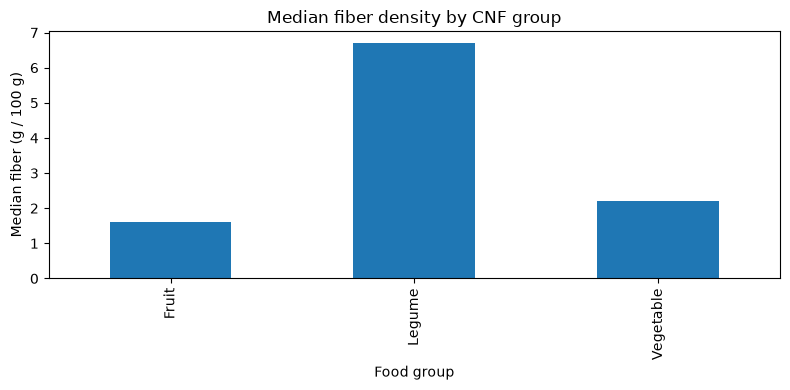

In [5]:
summary = cleaned.groupby('category').agg(
    entries=('Food_Code','size'),
    median_fiber=('fiber_per_100g','median'),
    mean_fiber=('fiber_per_100g','mean'),
    median_energy=('calories_per_100g','median'),
    max_fiber=('fiber_per_100g','max')
).round(2)
display(summary)
fig, ax = plt.subplots(figsize=(8,4))
summary['median_fiber'].plot(kind='bar',ax=ax)
ax.set(ylabel='Median fiber (g / 100 g)',xlabel='Food group',title='Median fiber density by CNF group')
plt.tight_layout(); plt.show()

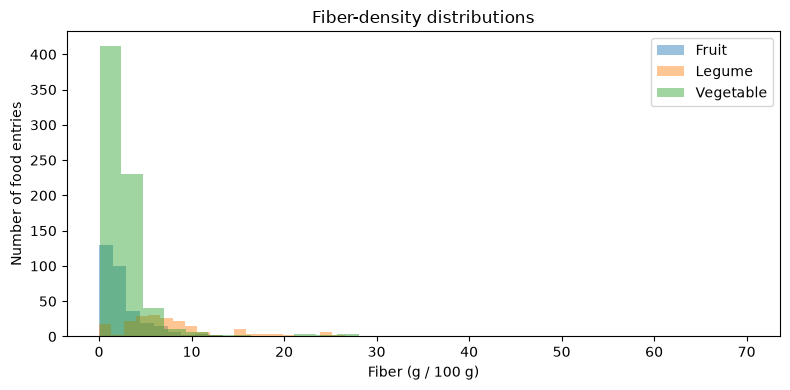

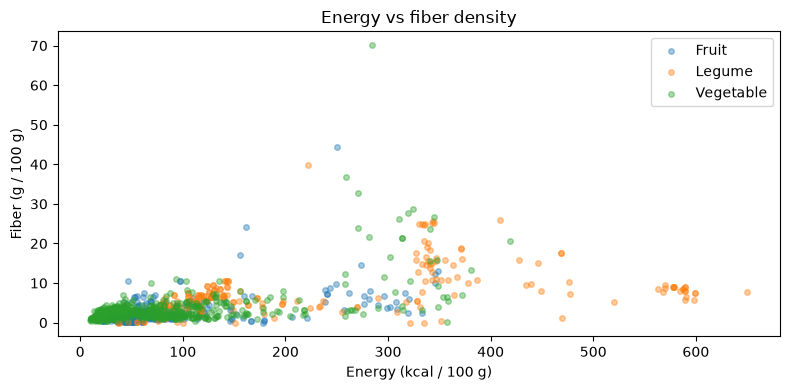

In [6]:
fig, ax=plt.subplots(figsize=(8,4))
for category, subset in cleaned.groupby('category'):
    ax.hist(subset['fiber_per_100g'].dropna(), bins=30, alpha=.45, label=category)
ax.set(xlabel='Fiber (g / 100 g)', ylabel='Number of food entries',title='Fiber-density distributions')
ax.legend(); plt.tight_layout(); plt.show()
fig, ax=plt.subplots(figsize=(8,4))
for category, subset in cleaned.groupby('category'):
    ax.scatter(subset['calories_per_100g'],subset['fiber_per_100g'],label=category,s=16,alpha=.4)
ax.set(xlabel='Energy (kcal / 100 g)',ylabel='Fiber (g / 100 g)',title='Energy vs fiber density')
ax.legend(); plt.tight_layout(); plt.show()

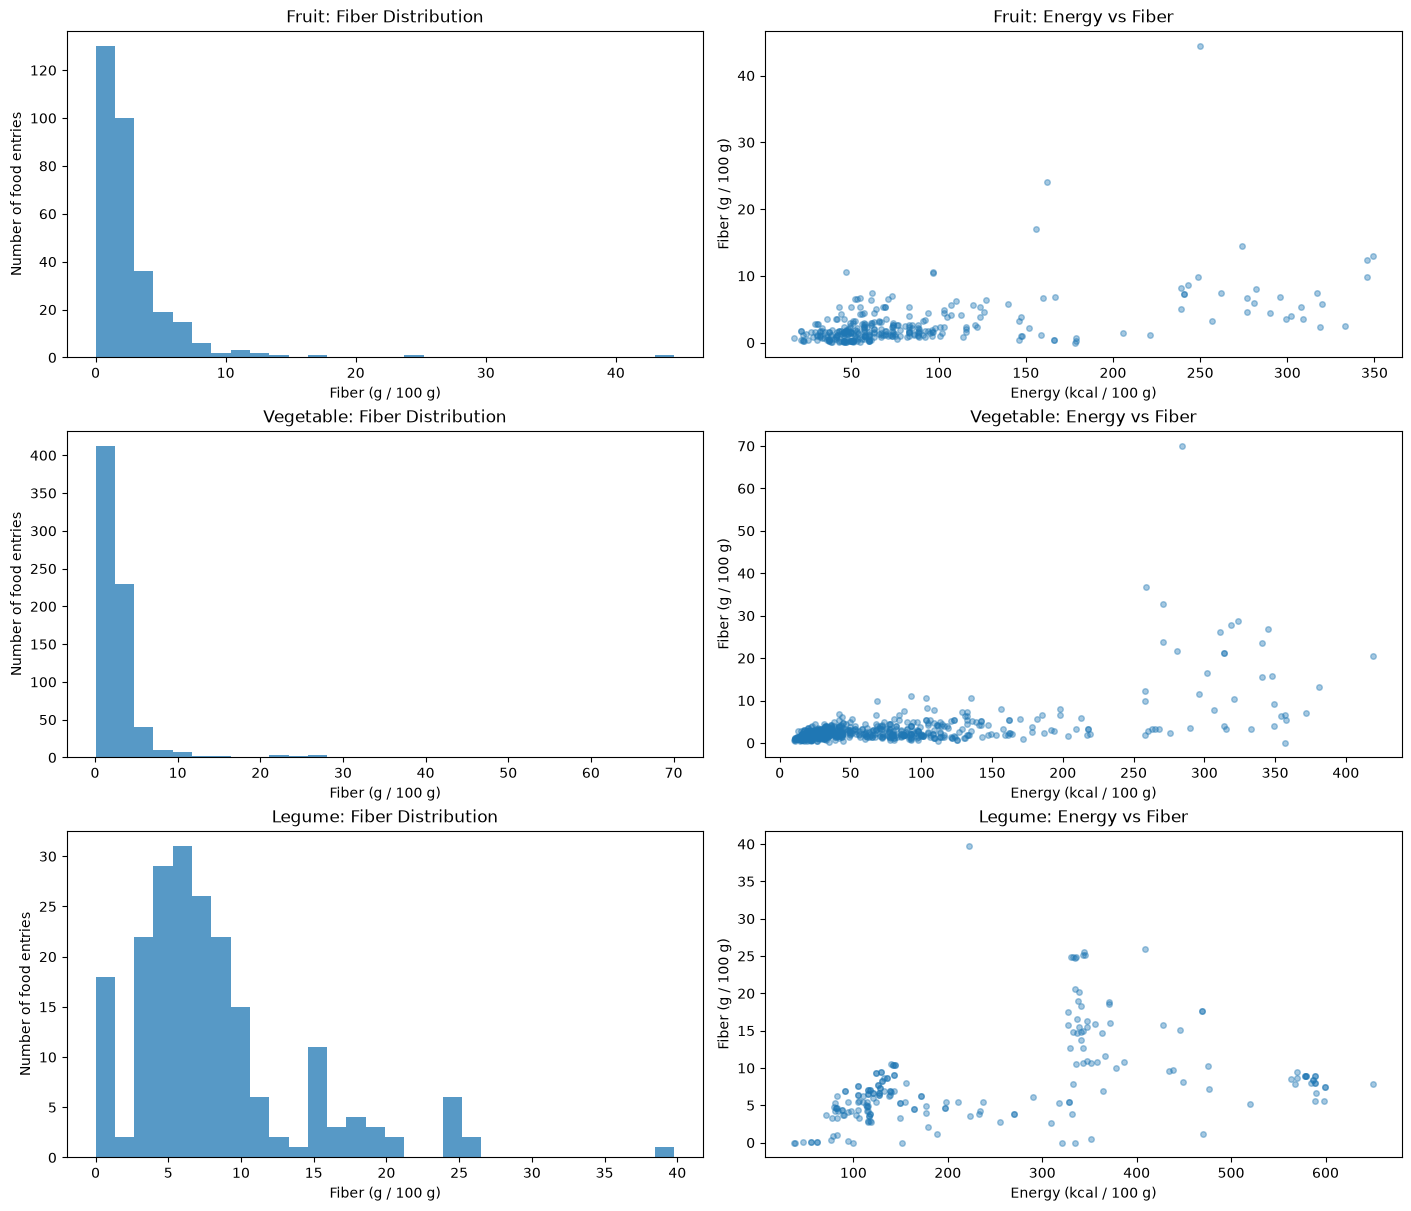

In [7]:
categories = ["Fruit", "Vegetable", "Legume"]

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14, 12),
    constrained_layout=True
)

for i, category in enumerate(categories):
    subset = cleaned[cleaned["category"] == category]

    # Histogram
    axes[i, 0].hist(
        subset["fiber_per_100g"].dropna(),
        bins=30,
        alpha=0.75
    )
    axes[i, 0].set(
        title=f"{category}: Fiber Distribution",
        xlabel="Fiber (g / 100 g)",
        ylabel="Number of food entries"
    )

    # Scatterplot
    axes[i, 1].scatter(
        subset["calories_per_100g"],
        subset["fiber_per_100g"],
        s=16,
        alpha=0.4
    )
    axes[i, 1].set(
        title=f"{category}: Energy vs Fiber",
        xlabel="Energy (kcal / 100 g)",
        ylabel="Fiber (g / 100 g)"
    )

plt.show()

In [13]:
top_fiber = (
    cleaned.nlargest(5, "fiber_per_100g")
    [["Food_Description_EN", "category", "fiber_per_100g"]]
)

display(top_fiber)

,Food_Description_EN,category,fiber_per_100g
3539,"Mushroom, fungi, Cloud ears, dried",Vegetable,70.1
5801,Baobab powder,Fruit,44.5
2359,"Carob (St. John's bread), flour",Legume,39.8
5181,"Seaweed, Canadian cultivated Emi-Tsunomata, dried",Vegetable,36.7
1562,"Parsley, freeze-dried",Vegetable,32.7


## 4. Why pure fiber ranking is not enough

Inspect high-fiber entries and their names. CNF includes different preparation states, peels, concentrates, and seasonings. A high **per-100-g** figure can come from dehydrated or low-water-content ingredients. It is not evidence that a 50–200 g portion is sensible. Examine the descriptions instead of automatically excluding extreme numeric values.

In [8]:
display(cleaned.nlargest(25,'fiber_per_100g')[['Food_Description_EN','category','fiber_per_100g','calories_per_100g']])

,Food_Description_EN,category,fiber_per_100g,calories_per_100g
3539,"Mushroom, fungi, Cloud ears, dried",Vegetable,70.1,284.0
5801,Baobab powder,Fruit,44.5,250.0
2359,"Carob (St. John's bread), flour",Legume,39.8,222.0
5181,"Seaweed, Canadian cultivated Emi-Tsunomata, dried",Vegetable,36.7,259.0
1562,"Parsley, freeze-dried",Vegetable,32.7,271.0
1617,"Pepper, hot chili, red, sun-dried",Vegetable,28.7,324.0
3944,"Celery flakes, dried",Vegetable,27.8,319.0
3520,"Pepper, pasilla, dried",Vegetable,26.8,345.0
1553,"Chives, freeze-dried",Vegetable,26.2,311.0
2417,"Beans, winged (goa beans), mature seeds, dry",Legume,25.9,409.0


## 5. Food-form feature engineering and modifier audit

Descriptions are comma-separated **text**, not a formally parsed preparation taxonomy. Inspect segment frequencies first; keyword rules classify preparation and prioritize practical whole foods. Dried fruits may be eaten as snacks but receive a penalty. Dried corn, uncooked dry pulses, and dehydrated vegetables are excluded from default recommendations (but retained in the audit table).


In [9]:
# Inspect comma-separated descriptive segments (not all segments are preparation methods)
modifiers = (cleaned["Food_Description_EN"].dropna().str.lower()
             .str.split(",").apply(lambda x: x[1:]).explode().str.strip())
display(modifiers.value_counts().rename_axis("modifier").reset_index(name="count").head(80))
reformed = add_food_features(cleaned)
display(reformed.food_form.value_counts().to_frame("count"))
display(reformed[["Food_Description_EN","food_form","is_dried_fruit","is_dry_staple","is_dehydrated_nonfruit"]].sample(min(18,len(reformed)),random_state=830))


,modifier,count
0,boiled,291
1,raw,284
2,drained,228
3,canned,208
4,frozen,165
...,...,...
75,pink,6
76,french),6
77,pods,6
78,stir-fried,6


,count
food_form,
Cooked,399
Processed / preserved,342
Raw / fresh,277
Dried / dehydrated,113
Other / unknown,109


,Food_Description_EN,food_form,is_dried_fruit,is_dry_staple,is_dehydrated_nonfruit
1386,"Lotus root, raw",Raw / fresh,False,False,False
1297,"Burdock root, raw",Raw / fresh,False,False,False
1626,"Artichoke (Globe, French), raw",Raw / fresh,False,False,False
4609,"Kale, boiled, drained, with salt",Cooked,False,False,False
4800,"Beans, snap (Italian, green or yellow), frozen...",Cooked,False,False,False
1497,"Succotash, canned with cream style corn",Processed / preserved,False,False,False
1323,"Chayote, fruit, boiled, drained",Cooked,False,False,False
953,"Peach, canned halves or slices, juice pack, so...",Processed / preserved,False,False,False
2390,"Peanut butter, chunk type, fat, sugar and salt...",Other / unknown,False,False,False
5115,"Corn, sweet, canned, drained solids, rinsed",Processed / preserved,False,False,False


## 6. Practicality screening — transparent heuristics

Exclude spices, peels/juice/minor cooking ingredients, uncooked dried staples, and dehydrated non-fruit ingredients from default *large-portion* combinations. Retain conventional dried fruits with a modest ranking penalty. This is an intentionally conservative product heuristic, **not** a verified edibility or popularity classifier. The full output preserves excluded rows and their flags for audit.


In [10]:
flags=["is_herb_spice","is_minor_ingredient","is_dry_pulse","is_dry_staple","is_dehydrated_nonfruit","is_dried_fruit","is_common_example","recommendation_eligible"]
display(reformed[flags].sum().to_frame("entries"))
display(reformed.loc[~reformed.recommendation_eligible,["Food_Description_EN","food_form","is_dry_staple","is_dehydrated_nonfruit","is_minor_ingredient"]].head(30))
print("Highest-fiber eligible foods — manually inspect these examples:")
display(reformed.loc[reformed.recommendation_eligible].nlargest(25,"fiber_per_100g")[["Food_Description_EN","food_form","fiber_per_100g","practicality_penalty"]])
print("Dried forms still eligible:")
display(reformed.loc[reformed.recommendation_eligible & (reformed.food_form=="Dried / dehydrated"),["Food_Description_EN","fiber_per_100g"]].head(30))


,entries
is_herb_spice,2
is_minor_ingredient,97
is_dry_pulse,39
is_dry_staple,40
is_dehydrated_nonfruit,48
is_dried_fruit,25
is_common_example,473
recommendation_eligible,1048


,Food_Description_EN,food_form,is_dry_staple,is_dehydrated_nonfruit,is_minor_ingredient
811,"Acerola (West Indian cherry), juice, raw",Processed / preserved,False,False,True
821,"Apple juice, canned or bottled, without added ...",Processed / preserved,False,False,True
822,"Apple juice, frozen concentrate, undiluted, wi...",Processed / preserved,False,False,True
823,"Apple juice, frozen concentrate, diluted, with...",Processed / preserved,False,False,True
827,"Apricot, canned halves with skin, juice pack, ...",Processed / preserved,False,False,True
840,"Banana, dehydrated or banana powder",Dried / dehydrated,False,False,True
859,"Cherry, sweet, canned, juice pack, solids and ...",Processed / preserved,False,False,True
866,"Cranberry orange relish, canned",Processed / preserved,False,False,False
868,"Currant, zante, dried",Dried / dehydrated,False,True,False
878,"Fruit cocktail (peach, pear, apricot, pineappl...",Processed / preserved,False,False,True


Highest-fiber eligible foods — manually inspect these examples:


,Food_Description_EN,food_form,fiber_per_100g,practicality_penalty
4519,"Rose hips, wild, Indigenous",Other / unknown,24.1,2
3837,"Indian, papad (papadum)",Other / unknown,18.6,2
1833,"Soybean kernels, roasted, unsalted",Cooked,17.7,0
2398,"Soybean kernels, roasted, salt added",Cooked,17.7,0
4449,"Chokecherry, raw, pitted",Raw / fresh,17.0,2
814,"Apple, dehydrated (low moisture), sulphured, u...",Dried / dehydrated,12.4,2
3522,"Fireweed, Indigenous, leaves, raw",Raw / fresh,10.6,2
4456,"Agave, cooked",Cooked,10.6,2
2485,"Beans, navy, mature seeds, boiled, salt added",Cooked,10.5,2
950,"Passion fruit, purple, raw",Raw / fresh,10.4,2


Dried forms still eligible:


,Food_Description_EN,fiber_per_100g
814,"Apple, dehydrated (low moisture), sulphured, u...",12.40
815,"Apple, dehydrated (low moisture), sulphured, c...",2.60
816,"Apple, dried, sulphured, uncooked",8.70
817,"Apple, dried, sulphured, stewed, no added sugar",2.00
818,"Apple, dried, sulphured, stewed, added sugar",1.90
833,"Apricot, dried, sulphured, uncooked",7.30
834,"Apricot, dried, sulphured, cooked, no added sugar",2.60
835,"Apricot, dried, sulphured, cooked, added sugar",4.10
875,"Fig, dried, uncooked",9.80
876,"Fig, dried, cooked",4.20


## 7. Before / after screening — selection bias check

Quantify which food groups and forms are more likely to be excluded. These *changes in the candidate set* are not nutritional changes to foods. A stringent filter may remove foods some users eat and may overrepresent items in the hand-built common-food list.

,before,median_before,after,median_after,excluded,excluded_pct
category,,,,,,
Fruit,317,1.6,243,1.90,74,23.3
Legume,206,6.7,140,5.57,66,32.0
Vegetable,717,2.2,665,2.10,52,7.3


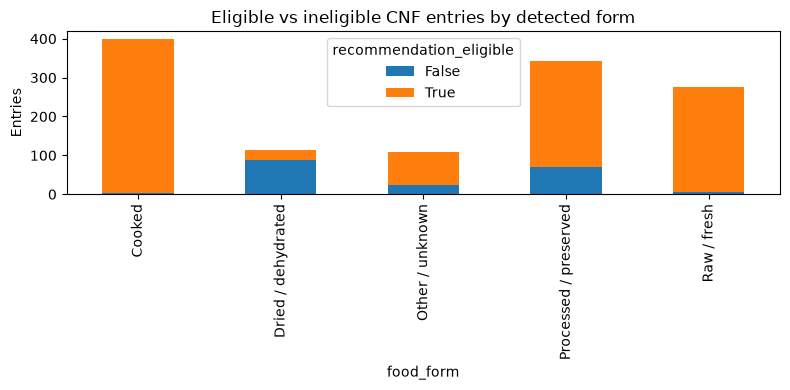

In [11]:
before=reformed.groupby('category').agg(before=('Food_Code','size'),median_before=('fiber_per_100g','median'))
after=reformed.loc[reformed.recommendation_eligible].groupby('category').agg(after=('Food_Code','size'),median_after=('fiber_per_100g','median'))
comparison=before.join(after,how='left').fillna({'after':0})
comparison['excluded']=comparison['before']-comparison['after']
comparison['excluded_pct']=(100*comparison['excluded']/comparison['before']).round(1)
display(comparison.round(2))
reformed.groupby(['food_form','recommendation_eligible']).size().unstack(fill_value=0).plot(kind='bar',stacked=True,figsize=(8,4))
plt.title('Eligible vs ineligible CNF entries by detected form');plt.ylabel('Entries');plt.tight_layout();plt.show()

## 8. Export recommendation-ready data

Keep the **entire** reformed table with audit flags so that the Streamlit app can restrict candidates using `recommendation_eligible` and prefer illustrative common foods when building its shortlist. This preserves excluded food records for debugging rather than silently deleting them.

Raw tables → cleaned nutrient export (`fiber_data.csv`) → augmented file (`fiber_data_recommendation.csv`). Recommendation candidates: eligible entries with strictly positive observed fiber.

In [12]:
destination=DATA_DIR / 'fiber_data_recommendation.csv'
reformed.to_csv(destination,index=False)
print('Saved:', destination, 'Rows:', len(reformed), 'Eligible:', reformed.recommendation_eligible.sum())
assert reformed['Food_Code'].is_unique
assert not reformed.loc[reformed.recommendation_eligible,['fiber_per_100g','calories_per_100g']].isna().any().any()

Saved: C:\Users\kuma0\Documents\CMSE830-Fall2026\Fiber-Intake-Explorer-Updated\data\fiber_data_recommendation.csv Rows: 1240 Eligible: 1048


## 9. Interpretation and limitations (verify your presentation statements)

The group medians, top-food examples, screened counts, and plots above provide the evidence for your presentation. Validate any numerical statements from the current results. Food descriptions are imperfect indicators of actual preparation. Commonness weights are hand-selected heuristics; they do not establish regional availability, costs, dietary suitability, customary servings, or measured consumption frequency. The app searches a limited candidate pool and does not guarantee globally optimal combinations. Future improvement: curated serving sizes, manual food-name validation, and consumption-frequency data.

**Validation distinction:** rule-trigger counts and manual examples document behavior but are not a formal precision/recall validation against hand-labeled ground truth. This is a limitation, not a measured classification accuracy. Official dataset nutrient entries can themselves include analytically measured, calculated, imputed, assumed-zero and provisional values (CNF 2026 Users’ Guide, pp. 13–14).